In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_excel('ApexPlanet_DataAnalytics_Dataset.xlsx')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head()

,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales
0,ORD100002,2025-02-25,CUST5529,Customer_227,30.0,Female,Bengaluru,Rice,Grocery,7,2829.77,19808.39
1,ORD100003,2025-10-14,CUST3127,Customer_182,63.0,Male,Bengaluru,Book,Education,5,27906.16,139530.80
2,ORD100004,2025-05-13,CUST8887,Customer_487,62.0,Female,Bengaluru,Book,Education,8,37491.06,299928.48
3,ORD100005,2025-12-02,CUST2515,Customer_470,65.0,Female,Kolkata,Mobile,Electronics,9,28541.36,256872.24
4,ORD100006,2025-11-20,CUST4796,Customer_380,44.0,Male,Bengaluru,Rice,Grocery,10,14036.59,140365.90


In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 1000
Number of columns: 12


In [5]:
print(df.columns.tolist())

['Order_ID', 'Order_Date', 'Customer_ID', 'Customer_Name', 'Age', 'Gender', 'City', 'Product', 'Category', 'Quantity', 'Unit_Price', 'Total_Sales']


In [6]:
df.describe(include='all')

,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales
count,1000,1000,1000,1000,980.000000,1000,987,1000,1000,1000.000000,1000.000000,1000.000000
unique,992,342,947,425,NaN,2,8,6,5,NaN,NaN,NaN
top,ORD100050,2025-04-16,CUST2515,Customer_359,NaN,Male,Patna,Mobile,Electronics,NaN,NaN,NaN
freq,9,10,3,8,NaN,511,135,184,354,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,41.360204,NaN,NaN,NaN,NaN,5.435000,25486.783410,139399.439650
std,NaN,NaN,NaN,NaN,13.822597,NaN,NaN,NaN,NaN,2.838632,14179.402361,114100.051546
min,NaN,NaN,NaN,NaN,18.000000,NaN,NaN,NaN,NaN,1.000000,145.780000,437.340000
25%,NaN,NaN,NaN,NaN,30.000000,NaN,NaN,NaN,NaN,3.000000,13895.722500,47066.632500
50%,NaN,NaN,NaN,NaN,41.000000,NaN,NaN,NaN,NaN,5.000000,25398.740000,108594.025000
75%,NaN,NaN,NaN,NaN,54.000000,NaN,NaN,NaN,NaN,8.000000,37512.382500,203722.882500


In [7]:

data_dictionary = """
# Data Dictionary
## ApexPlanet Data Analytics Internship - Task 1
### Dataset: Sales Dataset

| Column Name | Description | Data Type | Business Relevance |
|---|---|---|---|
| Order_ID | Unique identification number assigned to each order. | String | Helps identify and track individual orders. |
| Order_Date | Date on which the order was placed. | Date | Helps analyze sales trends over time. |
| Customer_ID | Unique identification number assigned to each customer. | String | Helps identify and track customers. |
| Customer_Name | Name of the customer who placed the order. | String | Helps identify customer records. |
| Age | Age of the customer. | Integer | Helps analyze customer demographics. |
| Gender | Gender of the customer. | String | Helps understand customer demographics. |
| City | City associated with the customer. | String | Helps analyze geographical sales patterns. |
| Product | Name of the product purchased. | String | Helps identify popular products. |
| Category | Category to which the purchased product belongs. | String | Helps compare category-wise sales. |
| Quantity | Number of units purchased in an order. | Integer | Helps measure product demand. |
| Unit_Price | Price of one unit of the purchased product. | Float | Helps understand product pricing. |
| Total_Sales | Total sales amount generated by the order. | Float | Helps measure revenue and sales performance. |

## Dataset Overview

- Dataset Name: Sales Dataset
- Source File: ApexPlanet_DataAnalytics_Dataset.xlsx
- Sheet Name: Sales_Dataset
- Number of Records: 1000
- Number of Columns: 12

## Purpose

This data dictionary describes the columns, meanings,
data types, and business relevance of the Sales Dataset.
It supports data understanding, cleaning, and analysis.
"""

# Create the data dictionary file
with open("data_dictionary.md", "w", encoding="utf-8") as file:
    file.write(data_dictionary)

print("Data dictionary created successfully!")


Data dictionary created successfully!


In [8]:
from google.colab import files

files.download("data_dictionary.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
# Check missing values in each column

print(df.isnull().sum())

Order_ID          0
Order_Date        0
Customer_ID       0
Customer_Name     0
Age              20
Gender            0
City             13
Product           0
Category          0
Quantity          0
Unit_Price        0
Total_Sales       0
dtype: int64


In [10]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)


Order_ID         0.0
Order_Date       0.0
Customer_ID      0.0
Customer_Name    0.0
Age              2.0
Gender           0.0
City             1.3
Product          0.0
Category         0.0
Quantity         0.0
Unit_Price       0.0
Total_Sales      0.0
dtype: float64


In [12]:
# Check exact duplicate rows

print("Duplicate rows:", df.duplicated().sum())

print("Repeated Order IDs:", df['Order_ID'].duplicated().sum())


Duplicate rows: 0
Repeated Order IDs: 8


In [13]:
# Find all repeated Order IDs

repeated_orders = df[
    df['Order_ID'].duplicated(keep=False)
].sort_values('Order_ID')

print(repeated_orders)

# Count occurrences of each repeated Order ID

print(
    df['Order_ID'].value_counts()
    .loc[lambda x: x > 1]
)

      Order_ID  Order_Date Customer_ID Customer_Name   Age  Gender       City  \
48   ORD100050  2025-10-03    CUST5523  Customer_432   NaN    Male       Pune   
118  ORD100050  2025-01-22    CUST3194  Customer_114  34.0    Male    Kolkata   
238  ORD100050  2025-03-01    CUST8467  Customer_104  23.0    Male  Bengaluru   
358  ORD100050  2025-02-11    CUST6467  Customer_181  24.0  Female       Pune   
478  ORD100050  2025-11-22    CUST8225  Customer_468  64.0    Male  Bengaluru   
598  ORD100050  2025-02-21    CUST8859   Customer_53   NaN    Male        NaN   
718  ORD100050  2025-11-06    CUST7824  Customer_190  31.0  Female     Mumbai   
838  ORD100050  2025-08-03    CUST5585  Customer_289  35.0    Male    Kolkata   
958  ORD100050  2025-02-09    CUST7188   Customer_89  62.0    Male  Bengaluru   

    Product     Category  Quantity  Unit_Price  Total_Sales  
48    Chair    Furniture         9    30834.87    277513.83  
118    Book    Education         2    25795.55     51591.10  
238

In [14]:
# Check data types of all columns

print("Data Types of Each Column:")
print(df.dtypes)

Data Types of Each Column:
Order_ID          object
Order_Date        object
Customer_ID       object
Customer_Name     object
Age              float64
Gender            object
City              object
Product           object
Category          object
Quantity           int64
Unit_Price       float64
Total_Sales      float64
dtype: object


In [15]:
# Check unique values in categorical columns

categorical_columns = [
    'Gender',
    'City',
    'Product',
    'Category'
]

for col in categorical_columns:
    print("\nColumn:", col)
    print(df[col].value_counts(dropna=False))


Column: Gender
Gender
Male      511
Female    489
Name: count, dtype: int64

Column: City
City
Patna        135
Kolkata      133
Mumbai       131
Delhi        125
Hyderabad    125
Bengaluru    122
Gaya         117
Pune          99
NaN           13
Name: count, dtype: int64

Column: Product
Product
Mobile    184
Book      178
Laptop    170
Chair     159
Shoes     156
Rice      153
Name: count, dtype: int64

Column: Category
Category
Electronics    354
Education      178
Furniture      159
Fashion        156
Grocery        153
Name: count, dtype: int64


In [16]:
# Check leading and trailing spaces

for col in ['Gender', 'City', 'Product', 'Category']:
    spaces = df[col].dropna().astype(str)

    count = (spaces != spaces.str.strip()).sum()

    print(col, ":", count, "values with extra spaces")

Gender : 0 values with extra spaces
City : 0 values with extra spaces
Product : 0 values with extra spaces
Category : 0 values with extra spaces


In [17]:
df[['Age', 'Quantity', 'Unit_Price', 'Total_Sales']].describe()

,Age,Quantity,Unit_Price,Total_Sales
count,980.000000,1000.000000,1000.000000,1000.000000
mean,41.360204,5.435000,25486.783410,139399.439650
std,13.822597,2.838632,14179.402361,114100.051546
min,18.000000,1.000000,145.780000,437.340000
25%,30.000000,3.000000,13895.722500,47066.632500
50%,41.000000,5.000000,25398.740000,108594.025000
75%,54.000000,8.000000,37512.382500,203722.882500
max,65.000000,10.000000,49997.530000,493677.500000


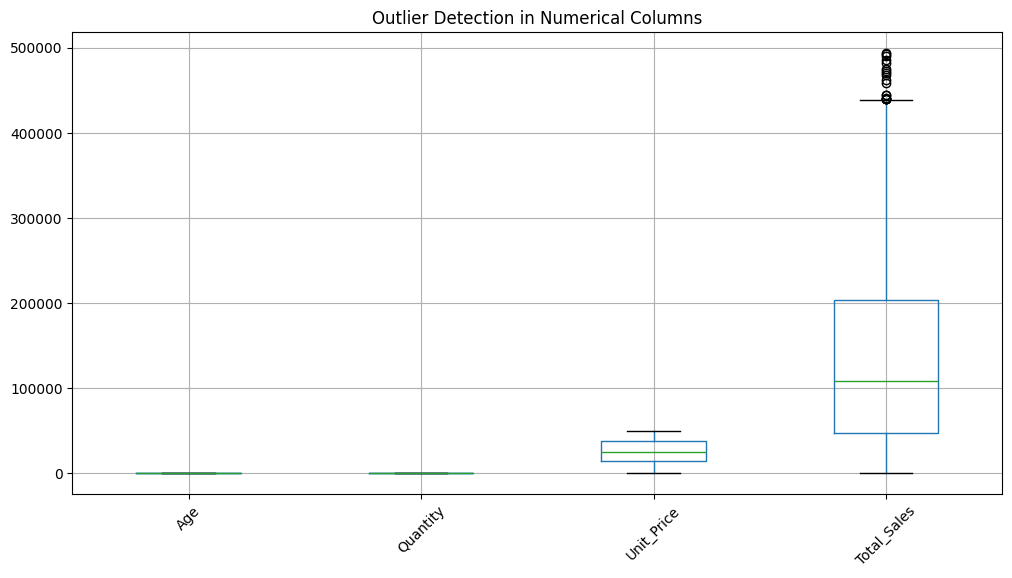

In [18]:
#Boxplot visualization

df[['Age', 'Quantity', 'Unit_Price', 'Total_Sales']].boxplot(
    figsize=(12, 6)
)

plt.title("Outlier Detection in Numerical Columns")
plt.xticks(rotation=45)
plt.show()

In [20]:
#IQR outlier detection
numeric_columns = [
    'Age',
    'Quantity',
    'Unit_Price',
    'Total_Sales'
]

for col in numeric_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) | (df[col] > upper)
    ]

    print("\nColumn:", col)
    print("Number of outliers:", len(outliers))
    print("Lower limit:", lower)
    print("Upper limit:", upper)



Column: Age
Number of outliers: 0
Lower limit: -6.0
Upper limit: 90.0

Column: Quantity
Number of outliers: 0
Lower limit: -4.5
Upper limit: 15.5

Column: Unit_Price
Number of outliers: 0
Lower limit: -21529.267499999998
Upper limit: 72937.3725

Column: Total_Sales
Number of outliers: 19
Lower limit: -187917.7425
Upper limit: 438707.2575


In [21]:
Q1 = df['Total_Sales'].quantile(0.25)
Q3 = df['Total_Sales'].quantile(0.75)

IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR

sales_outliers = df[df['Total_Sales'] > upper_limit]

print("Total number of outliers:", len(sales_outliers))

sales_outliers[['Order_ID', 'Product', 'Quantity',
                'Unit_Price', 'Total_Sales']]

Total number of outliers: 19


,Order_ID,Product,Quantity,Unit_Price,Total_Sales
50,ORD100052,Book,10,49367.75,493677.50
81,ORD100083,Laptop,9,48845.50,439609.50
150,ORD100152,Laptop,9,48833.27,439499.43
173,ORD100175,Rice,9,49390.42,444513.78
220,ORD100222,Shoes,10,49086.64,490866.40
364,ORD100366,Mobile,10,47493.59,474935.90
396,ORD100398,Mobile,9,48807.37,439266.33
432,ORD100434,Mobile,10,43997.22,439972.20
448,ORD100450,Book,10,43946.96,439469.60
462,ORD100464,Book,10,44045.66,440456.60


In [22]:
df['Calculated_Sales'] = df['Quantity'] * df['Unit_Price']

df['Sales_Difference'] = (
    df['Total_Sales'] - df['Calculated_Sales']
).round(2)

print("Incorrect sales records:",
      (df['Sales_Difference'] != 0).sum())

Incorrect sales records: 0


In [23]:
clean_df = df.copy()

print("Original dataset shape:", df.shape)
print("Working dataset shape:", clean_df.shape)

Original dataset shape: (1000, 14)
Working dataset shape: (1000, 14)


In [24]:
print(clean_df.isnull().sum())


Order_ID             0
Order_Date           0
Customer_ID          0
Customer_Name        0
Age                 20
Gender               0
City                13
Product              0
Category             0
Quantity             0
Unit_Price           0
Total_Sales          0
Calculated_Sales     0
Sales_Difference     0
dtype: int64


In [25]:
# Fill missing Age values with median
clean_df['Age'] = clean_df['Age'].fillna(
    clean_df['Age'].median()
)

# Fill missing City values with mode
clean_df['City'] = clean_df['City'].fillna(
    clean_df['City'].mode()[0]
)

# Check missing values after cleaning
print(clean_df.isnull().sum())

Order_ID            0
Order_Date          0
Customer_ID         0
Customer_Name       0
Age                 0
Gender              0
City                0
Product             0
Category            0
Quantity            0
Unit_Price          0
Total_Sales         0
Calculated_Sales    0
Sales_Difference    0
dtype: int64


In [26]:
clean_df['Order_Date'] = pd.to_datetime(clean_df['Order_Date'])

print(clean_df['Order_Date'].dtype)

datetime64[ns]


In [27]:
text_columns = [
    'Gender', 'City', 'Product', 'Category',
    'Customer_Name', 'Order_ID', 'Customer_ID'
]

for col in text_columns:
    clean_df[col] = clean_df[col].str.strip()

print("Extra spaces removed successfully.")

Extra spaces removed successfully.


In [28]:
clean_df['Gender'] = clean_df['Gender'].str.title()
clean_df['City'] = clean_df['City'].str.title()
clean_df['Product'] = clean_df['Product'].str.title()
clean_df['Category'] = clean_df['Category'].str.title()

print("Text formatting standardized successfully.")

print(clean_df['Gender'].unique())
print(clean_df['City'].unique())
print(clean_df['Category'].unique())

Text formatting standardized successfully.
['Female' 'Male']
['Bengaluru' 'Kolkata' 'Hyderabad' 'Patna' 'Mumbai' 'Delhi' 'Gaya' 'Pune']
['Grocery' 'Education' 'Electronics' 'Fashion' 'Furniture']


In [29]:
repeated_ids = clean_df[
    clean_df['Order_ID'].duplicated(keep=False)
]

print("Records with repeated Order_ID:")
print(repeated_ids[['Order_ID', 'Customer_ID', 'Order_Date', 'Product']])

Records with repeated Order_ID:
      Order_ID Customer_ID Order_Date Product
48   ORD100050    CUST5523 2025-10-03   Chair
118  ORD100050    CUST3194 2025-01-22    Book
238  ORD100050    CUST8467 2025-03-01    Book
358  ORD100050    CUST6467 2025-02-11    Rice
478  ORD100050    CUST8225 2025-11-22    Rice
598  ORD100050    CUST8859 2025-02-21  Laptop
718  ORD100050    CUST7824 2025-11-06    Rice
838  ORD100050    CUST5585 2025-08-03   Chair
958  ORD100050    CUST7188 2025-02-09  Mobile


In [30]:
print("Missing values:")
print(clean_df.isnull().sum())

print("\nExact duplicate rows:",
      clean_df.duplicated().sum())

print("\nDataset shape:", clean_df.shape)

Missing values:
Order_ID            0
Order_Date          0
Customer_ID         0
Customer_Name       0
Age                 0
Gender              0
City                0
Product             0
Category            0
Quantity            0
Unit_Price          0
Total_Sales         0
Calculated_Sales    0
Sales_Difference    0
dtype: int64

Exact duplicate rows: 0

Dataset shape: (1000, 14)


In [31]:
clean_df = clean_df.drop(
    columns=['Calculated_Sales', 'Sales_Difference']
)

print("Final dataset shape:", clean_df.shape)
print(clean_df.head())

Final dataset shape: (1000, 12)
    Order_ID Order_Date Customer_ID Customer_Name   Age  Gender       City  \
0  ORD100002 2025-02-25    CUST5529  Customer_227  30.0  Female  Bengaluru   
1  ORD100003 2025-10-14    CUST3127  Customer_182  63.0    Male  Bengaluru   
2  ORD100004 2025-05-13    CUST8887  Customer_487  62.0  Female  Bengaluru   
3  ORD100005 2025-12-02    CUST2515  Customer_470  65.0  Female    Kolkata   
4  ORD100006 2025-11-20    CUST4796  Customer_380  44.0    Male  Bengaluru   

  Product     Category  Quantity  Unit_Price  Total_Sales  
0    Rice      Grocery         7     2829.77     19808.39  
1    Book    Education         5    27906.16    139530.80  
2    Book    Education         8    37491.06    299928.48  
3  Mobile  Electronics         9    28541.36    256872.24  
4    Rice      Grocery        10    14036.59    140365.90  


In [32]:
clean_df.to_csv(
    'ApexPlanet_Cleaned_Dataset.csv',
    index=False
)

print("Cleaned dataset saved successfully!")


Cleaned dataset saved successfully!


In [33]:
from google.colab import files

files.download('ApexPlanet_Cleaned_Dataset.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>